In [1]:
import io
import re
import zipfile

import pandas as pd
import requests

url = (
    "https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/"
    "ftp/12_Industry_Portfolios_CSV.zip"
)

response = requests.get(url, timeout=30)
response.raise_for_status()

with zipfile.ZipFile(io.BytesIO(response.content)) as archive:
    csv_file = next(name for name in archive.namelist()
                    if name.lower().endswith(".csv"))
    lines = archive.read(csv_file).decode("latin-1").splitlines()

# Read the first monthly table, which contains value-weighted industry returns.
first_row = next(i for i, line in enumerate(lines)
                 if re.match(r"^\s*\d{6}\s*,", line))
end_row = first_row
while end_row < len(lines) and re.match(r"^\s*\d{6}\s*,", lines[end_row]):
    end_row += 1

monthly = pd.read_csv(
    io.StringIO("\n".join(lines[first_row - 1:end_row])),
    index_col=0,
)

monthly.columns = monthly.columns.str.strip()
monthly.index = pd.to_datetime(
    monthly.index.astype(str), format="%Y%m"
).to_period("M")
monthly.index.name = "Month"

# Mark missing values and convert percentages to decimals: 2.5% -> 0.025.
returns = monthly.replace([-99.99, -999], float("nan")) / 100

assert returns.shape[1] == 12, "Expected 12 industry columns."
print(f"{len(returns):,} months × {returns.shape[1]} industries")
print(f"Date range: {returns.index.min()} to {returns.index.max()}")
print(f"Missing values: {returns.isna().sum().sum()}")
display(returns.tail())

1,203 months × 12 industries
Date range: 1926-07 to 2026-09
Missing values: 0


,NoDur,Durbl,Manuf,Enrgy,Chems,BusEq,Telcm,Utils,Shops,Hlth,Money,Other
Month,,,,,,,,,,,,
2026-05,-0.0024,0.1203,0.0506,-0.0607,-0.0198,0.1199,-0.0146,-0.0497,-0.0289,0.0295,-0.0080,0.0005
2026-06,0.0158,-0.0286,0.1478,-0.0567,0.0191,-0.0501,-0.0898,0.0280,-0.0375,0.0752,0.0527,0.0137
2026-07,0.0324,-0.2050,-0.1274,0.1451,-0.0038,-0.0096,0.0318,-0.0179,0.0603,0.0073,0.0478,0.0069
2026-08,-0.0028,0.1314,-0.0309,0.0712,0.0178,0.0489,0.0778,-0.0282,-0.0308,0.0540,0.0111,0.0183
2026-09,-0.0485,-0.0477,-0.0179,-0.0205,-0.0450,0.0438,-0.0650,-0.0640,-0.0479,-0.0145,-0.0760,-0.0635


In [2]:
lookback = 60  # Reserve the first 5 years for estimating Markowitz weights.
test_returns = returns.iloc[lookback:]

n_industries = returns.shape[1]
equal_weight = 1 / n_industries

# With equal weights, the portfolio return is the average industry return.
equal_weight_gross = test_returns.mean(axis=1)

print(f"Weight per industry: {equal_weight:.2%}")
print(f"First test month: {equal_weight_gross.index[0]}")
display(equal_weight_gross.head().rename("Equal-weight return").to_frame()
        .style.format("{:.2%}"))

Weight per industry: 8.33%
First test month: 1931-07


,Equal-weight return
Month,
1931-07,-5.53%
1931-08,0.81%
1931-09,-30.08%
1931-10,9.36%
1931-11,-8.56%


In [3]:
import numpy as np
from scipy.optimize import minimize

risk_aversion = 10  # Fixed starting assumption, not tuned on the test results.

def markowitz_weights(history, risk_aversion=risk_aversion):
    mean_returns = history.mean().to_numpy()
    covariance = history.cov().to_numpy()
    n = history.shape[1]

    # Minimize the negative of expected return minus a risk penalty.
    def objective(w):
        expected_return = w @ mean_returns
        variance = w @ covariance @ w
        return -expected_return + (risk_aversion / 2) * variance

    result = minimize(
        objective,
        x0=np.full(n, 1 / n),
        method="SLSQP",
        bounds=[(0, 1)] * n,
        constraints={"type": "eq", "fun": lambda w: w.sum() - 1},
        options={"ftol": 1e-10},
    )
    if not result.success:
        raise RuntimeError(result.message)

    return pd.Series(result.x, index=history.columns, name="Markowitz weight")

# Use the 60 months BEFORE July 1931 to choose July's weights.
first_history = returns.iloc[:lookback]
first_weights = markowitz_weights(first_history)

print(f"Training window: {first_history.index[0]} to {first_history.index[-1]}")
print(f"Test month: {test_returns.index[0]}")
print(f"Weights sum to: {first_weights.sum():.2%}")
display(first_weights.sort_values(ascending=False).to_frame().style.format("{:.2%}"))

Training window: 1926-07 to 1931-06
Test month: 1931-07
Weights sum to: 100.00%


,Markowitz weight
Telcm,50.49%
NoDur,28.81%
Hlth,20.70%
Enrgy,0.00%
Utils,0.00%
Manuf,0.00%
Money,0.00%
BusEq,0.00%
Chems,0.00%
Durbl,0.00%


In [5]:
first_month = test_returns.index[0]
july_returns = test_returns.loc[first_month]

# Each industry's contribution is its weight times its actual July return.
contributions = first_weights * july_returns
markowitz_first_gross = contributions.sum()
equal_weight_first_gross = equal_weight_gross.loc[first_month]

print(f"Test month: {first_month}")
print(f"Markowitz return:    {markowitz_first_gross:.2%}")
print(f"Equal-weight return: {equal_weight_first_gross:.2%}")
print(f"Markowitz minus equal weight: "
      f"{100 * (markowitz_first_gross - equal_weight_first_gross):+.2f} percentage points")

Test month: 1931-07
Markowitz return:    -3.02%
Equal-weight return: -5.53%
Markowitz minus equal weight: +2.51 percentage points


In [6]:
# Re-estimate weights each month using only the previous 60 months.
weight_rows = []

for i in range(lookback, len(returns)):
    history = returns.iloc[i - lookback:i]
    weight_rows.append(markowitz_weights(history).to_numpy())

markowitz_weights_by_month = pd.DataFrame(
    weight_rows,
    index=test_returns.index,
    columns=returns.columns,
)

# Multiply each month's weights by that month's actual industry returns.
markowitz_gross = (markowitz_weights_by_month * test_returns).sum(axis=1)

gross_comparison = pd.DataFrame({
    "Equal Weight": equal_weight_gross,
    "Markowitz": markowitz_gross,
})

# Make sure the rolling backtest agrees with our manual July calculation.
assert np.isclose(markowitz_gross.iloc[0], markowitz_first_gross)

print(f"Test months: {len(gross_comparison):,}")
display(gross_comparison.head().style.format("{:.2%}"))

Test months: 1,143


,Equal Weight,Markowitz
Month,,
1931-07,-5.53%,-3.02%
1931-08,0.81%,0.41%
1931-09,-30.08%,-25.01%
1931-10,9.36%,5.43%
1931-11,-8.56%,-5.82%


In [7]:
equal_weights_by_month = pd.DataFrame(
    equal_weight,
    index=test_returns.index,
    columns=test_returns.columns,
)

def monthly_turnover(target_weights, asset_returns):
    # Compute each holding's weight after the month's returns.
    holdings_after_returns = target_weights * (1 + asset_returns)
    end_weights = holdings_after_returns.div(
        holdings_after_returns.sum(axis=1), axis=0
    )

    # This month's trades start from last month's ending weights.
    pre_trade_weights = end_weights.shift(1)
    turnover = 0.5 * (target_weights - pre_trade_weights).abs().sum(
        axis=1, min_count=1
    )
    turnover.iloc[0] = 0.0  # Exclude initial setup costs for both strategies.
    return turnover

turnover = pd.DataFrame({
    "Equal Weight": monthly_turnover(equal_weights_by_month, test_returns),
    "Markowitz": monthly_turnover(markowitz_weights_by_month, test_returns),
})

cost_rate = 0.001  # Assume 10 basis points per dollar reallocated.
trading_costs = turnover * cost_rate
net_comparison = (1 - trading_costs) * (1 + gross_comparison) - 1

print("Average monthly turnover (excluding initial setup):")
display(turnover.iloc[1:].mean().to_frame("Average").style.format("{:.2%}"))

print("First five monthly returns after estimated costs:")
display(net_comparison.head().style.format("{:.2%}"))

Average monthly turnover (excluding initial setup):


,Average
Equal Weight,1.12%
Markowitz,9.77%


First five monthly returns after estimated costs:


,Equal Weight,Markowitz
Month,,
1931-07,-5.53%,-3.02%
1931-08,0.81%,0.39%
1931-09,-30.08%,-25.01%
1931-10,9.36%,5.40%
1931-11,-8.56%,-5.83%


In [8]:
# Growth of $1 after estimated trading costs.
wealth = (1 + net_comparison).cumprod()
months = len(net_comparison)

# Include the starting $1 as a peak so a first-month loss counts.
running_peak = wealth.cummax().clip(lower=1.0)
drawdown = wealth / running_peak - 1

monthly_vol = net_comparison.std(ddof=1)

summary = pd.DataFrame({
    "Annualized Return (CAGR)": wealth.iloc[-1] ** (12 / months) - 1,
    "Annualized Volatility": monthly_vol * np.sqrt(12),
    "Sharpe Ratio (0% risk-free)": (
        net_comparison.mean() / monthly_vol * np.sqrt(12)
    ),
    "Maximum Drawdown": drawdown.min(),
    "Average Monthly Turnover": turnover.iloc[1:].mean(),
})

display(summary.style.format({
    "Annualized Return (CAGR)": "{:.2%}",
    "Annualized Volatility": "{:.2%}",
    "Sharpe Ratio (0% risk-free)": "{:.3f}",
    "Maximum Drawdown": "{:.2%}",
    "Average Monthly Turnover": "{:.2%}",
}))

,Annualized Return (CAGR),Annualized Volatility,Sharpe Ratio (0% risk-free),Maximum Drawdown,Average Monthly Turnover
Equal Weight,11.06%,17.91%,0.677,-66.81%,1.12%
Markowitz,10.87%,15.63%,0.742,-56.69%,9.77%


In [9]:
cost_scenarios = []

for cost_bps in [0, 10, 25, 50, 100]:
    rate = cost_bps / 10_000
    net = (1 - turnover * rate) * (1 + gross_comparison) - 1
    sharpe = net.mean() / net.std(ddof=1) * np.sqrt(12)

    cost_scenarios.append({
        "Cost (bps per dollar reallocated)": cost_bps,
        "Equal Weight Sharpe": sharpe["Equal Weight"],
        "Markowitz Sharpe": sharpe["Markowitz"],
        "Markowitz Advantage": sharpe["Markowitz"] - sharpe["Equal Weight"],
    })

cost_sensitivity = pd.DataFrame(cost_scenarios).set_index(
    "Cost (bps per dollar reallocated)"
)
display(cost_sensitivity.style.format("{:.3f}"))

,Equal Weight Sharpe,Markowitz Sharpe,Markowitz Advantage
Cost (bps per dollar reallocated),,,
0,0.677,0.749,0.072
10,0.677,0.742,0.065
25,0.676,0.730,0.055
50,0.674,0.712,0.038
100,0.670,0.674,0.004


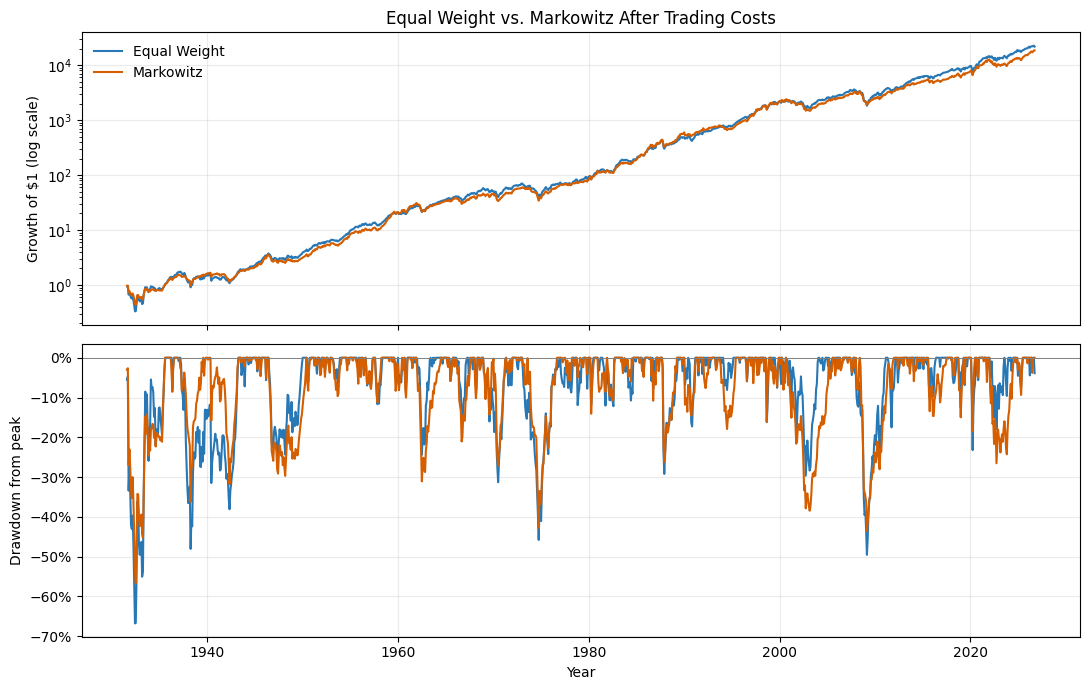

In [10]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

dates = wealth.index.to_timestamp(how="end")
fig, (ax_wealth, ax_dd) = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
colors = {"Equal Weight": "#2878B5", "Markowitz": "#D55E00"}

for strategy, color in colors.items():
    ax_wealth.plot(dates, wealth[strategy], label=strategy, color=color)
    ax_dd.plot(dates, drawdown[strategy], color=color)

ax_wealth.set(title="Equal Weight vs. Markowitz After Trading Costs",
              ylabel="Growth of $1 (log scale)", yscale="log")
ax_wealth.legend(frameon=False)

ax_dd.set(ylabel="Drawdown from peak", xlabel="Year")
ax_dd.yaxis.set_major_formatter(PercentFormatter(1))
ax_dd.axhline(0, color="gray", linewidth=0.7)

for ax in (ax_wealth, ax_dd):
    ax.grid(alpha=0.25)

fig.tight_layout()
fig.savefig("equal_weight_vs_markowitz.png", dpi=200, bbox_inches="tight")
plt.show()

In [11]:
midpoint = len(net_comparison) // 2
halves = [net_comparison.iloc[:midpoint], net_comparison.iloc[midpoint:]]

rows = []
for period in halves:
    sharpe = np.sqrt(12) * period.mean() / period.std(ddof=1)

    rows.append({
        "Period": f"{period.index[0]} to {period.index[-1]}",
        "Equal Weight Sharpe": sharpe["Equal Weight"],
        "Markowitz Sharpe": sharpe["Markowitz"],
        "Markowitz Advantage": sharpe["Markowitz"] - sharpe["Equal Weight"],
    })

display(pd.DataFrame(rows).set_index("Period").style.format("{:.3f}"))

,Equal Weight Sharpe,Markowitz Sharpe,Markowitz Advantage
Period,,,
1931-07 to 1979-01,0.551,0.635,0.084
1979-02 to 2026-09,0.872,0.864,-0.008


## Conclusion

Across 1,143 out-of-sample months, long-only Markowitz had a higher annualized Sharpe ratio than equal weight (0.742 vs. 0.677), assuming a 0% risk-free rate and a trading cost of 10 basis points per dollar reallocated. It also had a smaller maximum drawdown (−56.69% vs. −66.81%). Equal weight compounded slightly faster (11.06% vs. 10.87% annually) and required much less monthly turnover (1.12% vs. 9.77%).

The Sharpe advantage was not consistent across time. Markowitz led by 0.084 in the first half, but equal weight led by 0.008 in the second. In the full-period cost sensitivity check, raising the assumed cost from 10 to 100 basis points narrowed Markowitz’s Sharpe lead from 0.065 to 0.004.

Under these assumptions, optimization reduced volatility and the worst drawdown, but it did not improve compound growth or consistently deliver better risk-adjusted returns. Equal weight remained a competitive benchmark.